# 4. Modelado con scikit-learn (muestras escalonadas)

**Diseño.**
1. Búsqueda bayesiana (Optuna, TPE) del MLP sobre una muestra de entrenamiento, con validación
   temporal (día 29) y la codificación principal (hashing $2^{14}$).
2. Corridas finales con los mejores hiperparámetros en muestras de 100 mil, 1 millón y
   10 millones de filas (anidadas), para cada codificación y modelo:
   - `sgd`: regresión logística por SGD (línea base lineal).
   - `hgb`: `HistGradientBoostingClassifier` (línea base no lineal; requiere matriz densa, por eso
     se usa con frecuencia y target encoding).
   - `mlp`: `MLPClassifier` (ReLU, Adam) con **parada temprana temporal**.
3. Semillas: 5 repeticiones en los tamaños `sk_seed_sizes` (media, desviación, IC 95 %); una en
   el resto por costo.
4. Ablaciones: dimensión del hashing, cruces, profundidad, ponderación de clases y la parada
   temprana interna del enunciado.

**Sobre `early_stopping=True`.** El enunciado lo propone, pero scikit-learn separa al azar un
10 % del entrenamiento para decidir cuándo parar, lo que mezcla días y contradice la división
temporal. Se reemplaza por entrenamiento época a época (`partial_fit`) con parada según la log
loss del día 29, y la variante del enunciado se conserva como ablación para medir la diferencia.

Las corridas se registran en `results/runs_sklearn.jsonl` y el notebook se puede reanudar: lo que
ya está registrado no se recalcula.

In [1]:
import sys, json, time
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent / "src") if Path.cwd().name == "notebooks" else str(Path.cwd() / "src"))
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from ctr.nbutils import setup, savefig, show, run_key, done_keys, save_preds, SERIES, MODEL_COLOR, ENC_COLOR, MUTED
from ctr import data, models_sk as MS
from ctr.features import CTRFeaturizer
from ctr.experiments import run_sk_model
from ctr.bench import append_jsonl, read_jsonl, measure

cfg, RES, FIG = setup()
RUNS = RES / "runs_sklearn.jsonl"
ABL = RES / "ablaciones_sklearn.jsonl"
va, te = data.eval_sets(cfg)
yva, yte = va["click"].to_numpy(), te["click"].to_numpy()
te.select("id").write_parquet(RES / "test_ids.parquet")   # orden de referencia de la prueba
DIM = cfg["hash_dim_main"]
print(f"validación: {len(yva):,} filas (CTR {yva.mean():.4f}) | prueba: {len(yte):,} filas (CTR {yte.mean():.4f})")

Perfil: colab  |  resultados en: /content/deep-learning-01-ctr-mlp/results


validación: 1,000,000 filas (CTR 0.1568) | prueba: 4,218,938 filas (CTR 0.1693)


## 4.1 Búsqueda de hiperparámetros con Optuna (validación temporal)

In [2]:
best_path = RES / "mlp_best_params.json"
n_opt = cfg["optuna_train_size"]
tr = data.read_sample(cfg, "train", n_opt)
feat = CTRFeaturizer(cfg.high_card, cfg.low_card, cfg["rare_min_count"])
c_tr, Xtr = feat.fit_transform(tr, tr["click"].to_numpy(), "hash", DIM)
Xva = feat.transform_codes(feat.encode(va), "hash", DIM)
ytr = tr["click"].to_numpy()

if best_path.exists():
    best = json.loads(best_path.read_text())
    trials = pd.read_csv(RES / "optuna_trials.csv")
else:
    t0 = time.perf_counter()
    study = MS.optuna_search(Xtr, ytr, Xva, yva, cfg["mlp_search_space"], cfg["optuna_trials"],
                             cfg["seed_base"], cfg["max_epochs"], cfg["patience"])
    trials = study.trials_dataframe()
    trials.to_csv(RES / "optuna_trials.csv", index=False)
    best = dict(study.best_params)
    best["val_log_loss"] = study.best_value
    best["busqueda_s"] = time.perf_counter() - t0
    best_path.write_text(json.dumps(best, indent=2))
print(json.dumps(best, indent=2))
show(trials.sort_values("value").head(10))

{
  "hidden_layer_sizes": "100",
  "alpha": 0.04667993294288689,
  "learning_rate_init": 0.00014659067019501246,
  "batch_size": 2048,
  "val_log_loss": 0.3860083222389221,
  "busqueda_s": 2026.7151061429997
}


,number,value,datetime_start,datetime_complete,duration,params_alpha,params_batch_size,params_hidden_layer_sizes,params_learning_rate_init,user_attrs_best_epoch,user_attrs_fit_s,user_attrs_val_auc,system_attrs_tpe:relative_params:0,state
17,17,0.3860,2026-11-07 10:57:49.542019,2026-11-07 10:59:05.569420,0 days 00:01:16.027401,0.0467,2048,100,0.0001,13,76.0227,0.7351,"{""alpha"": 0.04667993294288689, ""batch_size"": 2...",COMPLETE
16,16,0.3860,2026-11-07 10:56:40.632110,2026-11-07 10:57:49.541921,0 days 00:01:08.909811,0.0309,2048,100,0.0001,12,68.9059,0.7349,"{""alpha"": 0.03087280229803585, ""batch_size"": 2...",COMPLETE
24,24,0.3861,2026-11-07 11:06:20.103885,2026-11-07 11:07:37.141525,0 days 00:01:17.037640,0.0122,2048,100,0.0001,15,77.0328,0.7348,"{""alpha"": 0.012190839585138929, ""batch_size"": ...",COMPLETE
21,21,0.3861,2026-11-07 11:04:12.029166,2026-11-07 11:05:09.863946,0 days 00:00:57.834780,0.0610,2048,100,0.0003,10,57.8283,0.7352,"{""alpha"": 0.06096898289718737, ""batch_size"": 2...",COMPLETE
18,18,0.3861,2026-11-07 10:59:05.569652,2026-11-07 11:00:15.625423,0 days 00:01:10.055771,0.0794,2048,100,0.0002,12,70.0501,0.7351,"{""alpha"": 0.07942305699493586, ""batch_size"": 2...",COMPLETE
20,20,0.3862,2026-11-07 11:03:18.930762,2026-11-07 11:04:12.029069,0 days 00:00:53.098307,0.0099,2048,100,0.0002,8,53.0925,0.7347,"{""alpha"": 0.009876464948781432, ""batch_size"": ...",COMPLETE
13,13,0.3863,2026-11-07 10:52:09.842454,2026-11-07 10:53:54.850971,0 days 00:01:45.008517,0.0008,2048,256-128,0.0001,5,105.0047,0.7348,"{""alpha"": 0.0007663807583474999, ""batch_size"":...",COMPLETE
14,14,0.3865,2026-11-07 10:53:54.851054,2026-11-07 10:55:30.364874,0 days 00:01:35.513820,0.0016,2048,256-128,0.0001,4,95.5093,0.7343,"{""alpha"": 0.0015734609650472887, ""batch_size"":...",COMPLETE
11,11,0.3865,2026-11-07 10:51:02.292447,2026-11-07 10:51:48.066654,0 days 00:00:45.774207,0.0003,2048,100-50,0.0002,5,45.7697,0.7342,"{""alpha"": 0.00033983393356914907, ""batch_size""...",COMPLETE
19,19,0.3867,2026-11-07 11:00:15.625530,2026-11-07 11:03:18.930689,0 days 00:03:03.305159,0.0264,512,100,0.0001,8,183.2998,0.7347,"{""alpha"": 0.0263930960530446, ""batch_size"": 51...",COMPLETE


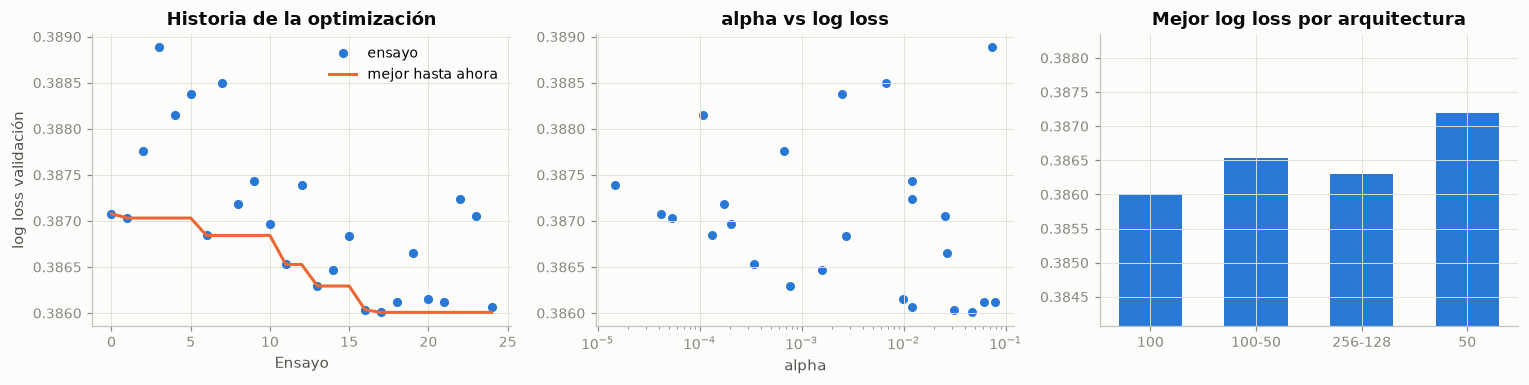

In [3]:
fig, axs = plt.subplots(1, 3, figsize=(14, 3.6))
axs[0].plot(trials["number"], trials["value"], "o", color=SERIES[0], markersize=5, label="ensayo")
axs[0].plot(trials["number"], trials["value"].cummin(), color=SERIES[1], label="mejor hasta ahora")
axs[0].set_title("Historia de la optimización"); axs[0].set_xlabel("Ensayo"); axs[0].set_ylabel("log loss validación"); axs[0].legend()
axs[1].scatter(trials["params_alpha"], trials["value"], color=SERIES[0], s=24)
axs[1].set_xscale("log"); axs[1].set_title("alpha vs log loss"); axs[1].set_xlabel("alpha")
g = trials.groupby("params_hidden_layer_sizes")["value"].min()
axs[2].bar(g.index.astype(str), g.values, color=SERIES[0], width=0.6)
axs[2].set_ylim(g.min() * 0.995, g.max() * 1.003); axs[2].set_title("Mejor log loss por arquitectura")
savefig(fig, FIG, "04_optuna")

PARAMS = {k: best[k] for k in ["hidden_layer_sizes", "alpha", "learning_rate_init", "batch_size"]}

## 4.2 Corridas finales: tamaños × codificaciones × modelos × semillas

In [4]:
ENCODINGS = ["hash", "freq", "target"]
MODELS = {"hash": ["sgd", "mlp"], "freq": ["sgd", "hgb", "mlp"], "target": ["sgd", "hgb", "mlp"]}
done = done_keys(RUNS)
for n in cfg["sk_sizes"]:
    n_avail = data.split_sizes(cfg)["train"]
    if n > n_avail:
        print(f"Se omite n={n:,}: el entrenamiento solo tiene {n_avail:,} filas"); continue
    seeds = cfg.seeds if n in cfg["sk_seed_sizes"] else [cfg["seed_base"]]
    pending = [(e, m, s) for e in ENCODINGS for m in MODELS[e] for s in seeds
               if run_key(fw="sklearn", model=m, enc=e, n=n, seed=s, cw="none") not in done]
    if not pending:
        continue
    prep = {}
    with measure(prep, "lectura", n):
        tr = data.read_sample(cfg, "train", n)
    ytr = tr["click"].to_numpy()
    feat = CTRFeaturizer(cfg.high_card, cfg.low_card, cfg["rare_min_count"])
    with measure(prep, "ajuste_vocab", n):
        feat.fit(tr)
        c_tr = feat.encode(tr)
    c_va, c_te = feat.encode(va), feat.encode(te)
    del tr
    for enc in ENCODINGS:
        if not any(p[0] == enc for p in pending):
            continue
        with measure(prep, f"transform_{enc}", n):
            Xtr = feat.transform_codes(c_tr, enc, DIM, y=ytr, fit=True)
        Xva_, Xte_ = feat.transform_codes(c_va, enc, DIM), feat.transform_codes(c_te, enc, DIM)
        for (e, m, s) in pending:
            if e != enc:
                continue
            key = run_key(fw="sklearn", model=m, enc=e, n=n, seed=s, cw="none")
            t0 = time.perf_counter()
            rec, p_te, clf = run_sk_model(m, Xtr, ytr, Xva_, yva, Xte_, yte, s, PARAMS,
                                          max_epochs=cfg["max_epochs"], patience=cfg["patience"])
            rec.update({"key": key, "encoding": e, "hash_dim": DIM if e == "hash" else None, "n": n,
                        "lectura_s": prep["lectura_s"], "prep_s": prep["ajuste_vocab_s"] + prep[f"transform_{enc}_s"],
                        "prep_peak_mb": max(prep["ajuste_vocab_peak_mb"], prep[f"transform_{enc}_peak_mb"])})
            if s == cfg["seed_base"]:
                rec["pred_file"] = save_preds(RES, key, p_te)
                if m == "mlp":
                    rec["history"] = clf.history_
            append_jsonl(RUNS, rec)
            print(f"n={n:>10,} {e:6s} {m:4s} seed={s} AUC={rec['roc_auc']:.4f} logloss={rec['log_loss']:.4f} "
                  f"train={rec['train_s']:.1f}s  ({time.perf_counter() - t0:.0f}s)")

n=   100,000 hash   sgd  seed=42 AUC=0.7165 logloss=0.4137 train=3.3s  (12s)


n=   100,000 hash   sgd  seed=43 AUC=0.7178 logloss=0.4151 train=4.5s  (14s)


n=   100,000 hash   sgd  seed=44 AUC=0.7171 logloss=0.4123 train=3.6s  (12s)


n=   100,000 hash   sgd  seed=45 AUC=0.7126 logloss=0.4140 train=3.6s  (12s)


n=   100,000 hash   sgd  seed=46 AUC=0.7187 logloss=0.4121 train=3.5s  (12s)


n=   100,000 hash   mlp  seed=42 AUC=0.7168 logloss=0.4109 train=41.1s  (55s)


... (78 outputs left out)

n=10,000,000 freq   mlp  seed=42 AUC=0.6717 logloss=0.4401 train=184.0s  (193s)


n=10,000,000 target sgd  seed=42 AUC=0.7259 logloss=0.4081 train=158.3s  (166s)


n=10,000,000 target hgb  seed=42 AUC=0.7391 logloss=0.4008 train=165.2s  (216s)


n=10,000,000 target mlp  seed=42 AUC=0.7253 logloss=0.4086 train=437.3s  (446s)


In [5]:
runs = read_jsonl(RUNS)
from ctr.metrics import summarize_runs
tabla = summarize_runs(runs, ["n", "encoding", "model"], ["roc_auc", "pr_auc", "log_loss", "brier", "ece", "f1", "train_s", "train_peak_mb"])
tabla.to_csv(RES / "tabla_sklearn.csv", index=False)
show(tabla[["n", "encoding", "model", "n_semillas", "roc_auc_media", "roc_auc_sd", "roc_auc_ic",
            "pr_auc_media", "log_loss_media", "ece_media", "f1_media", "train_s_media", "train_peak_mb_media"]], 60)

,n,encoding,model,n_semillas,roc_auc_media,roc_auc_sd,roc_auc_ic,pr_auc_media,log_loss_media,ece_media,f1_media,train_s_media,train_peak_mb_media
0,100000,freq,hgb,5,0.7128,0.0000,"[0.7128, 0.7128]",0.3388,0.4132,0.0066,0.3962,38.2304,4470.8805
1,100000,freq,mlp,5,0.6630,0.0061,"[0.6554, 0.6705]",0.2903,0.4328,0.0186,0.3472,14.3909,4601.8891
2,100000,freq,sgd,5,0.6541,0.0027,"[0.6507, 0.6575]",0.2777,0.4333,0.0190,0.3461,2.6407,4247.4688
3,100000,hash,mlp,5,0.7171,0.0007,"[0.7162, 0.7180]",0.3460,0.4110,0.0111,0.3914,37.1540,5127.0188
4,100000,hash,sgd,5,0.7166,0.0024,"[0.7136, 0.7195]",0.3429,0.4134,0.0184,0.3966,3.6984,4756.3539
5,100000,target,hgb,5,0.7204,0.0000,"[0.7204, 0.7204]",0.3427,0.4096,0.0074,0.4006,41.0711,4410.3281
6,100000,target,mlp,5,0.6861,0.0070,"[0.6774, 0.6948]",0.3199,0.4220,0.0128,0.3650,14.6136,4506.8992
7,100000,target,sgd,5,0.7121,0.0007,"[0.7112, 0.7130]",0.3385,0.4137,0.0142,0.3940,2.6400,4184.1570
8,1000000,freq,hgb,5,0.7254,0.0010,"[0.7241, 0.7266]",0.3533,0.4076,0.0066,0.4092,53.0123,4603.7539
9,1000000,freq,mlp,5,0.6826,0.0043,"[0.6773, 0.6879]",0.3140,0.4254,0.0153,0.3613,52.4163,4706.4695


## 4.3 Curvas de aprendizaje y de costo

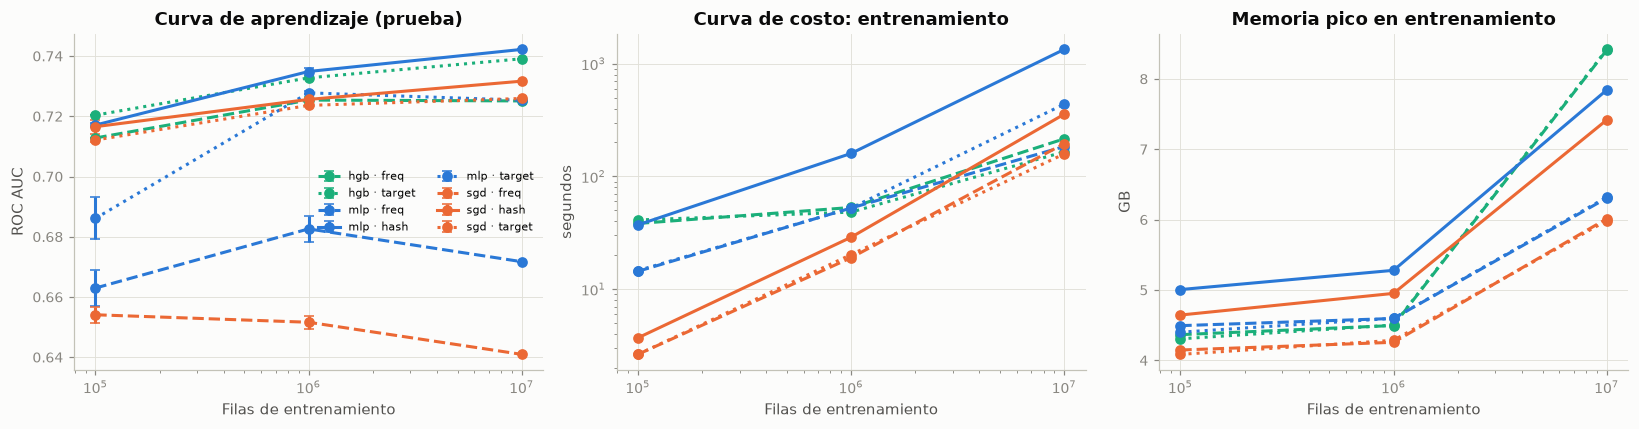

In [6]:
agg = runs.groupby(["model", "encoding", "n"]).agg(auc=("roc_auc", "mean"), auc_sd=("roc_auc", "std"),
                                                   t=("train_s", "mean"), mem=("train_peak_mb", "mean")).reset_index()
fig, axs = plt.subplots(1, 3, figsize=(15, 4))
styles = {"hash": "-", "freq": "--", "target": ":"}
for (m, e), g in agg.groupby(["model", "encoding"]):
    lab = f"{m} · {e}"
    axs[0].errorbar(g["n"], g["auc"], yerr=g["auc_sd"].fillna(0), color=MODEL_COLOR[m], linestyle=styles[e], marker="o", label=lab, capsize=3)
    axs[1].plot(g["n"], g["t"], color=MODEL_COLOR[m], linestyle=styles[e], marker="o", label=lab)
    axs[2].plot(g["n"], g["mem"] / 1024, color=MODEL_COLOR[m], linestyle=styles[e], marker="o", label=lab)
for ax, t, yl in zip(axs, ["Curva de aprendizaje (prueba)", "Curva de costo: entrenamiento", "Memoria pico en entrenamiento"],
                     ["ROC AUC", "segundos", "GB"]):
    ax.set_xscale("log"); ax.set_xlabel("Filas de entrenamiento"); ax.set_title(t); ax.set_ylabel(yl)
axs[1].set_yscale("log"); axs[0].legend(fontsize=7, ncols=2)
savefig(fig, FIG, "04_curvas_aprendizaje_costo")

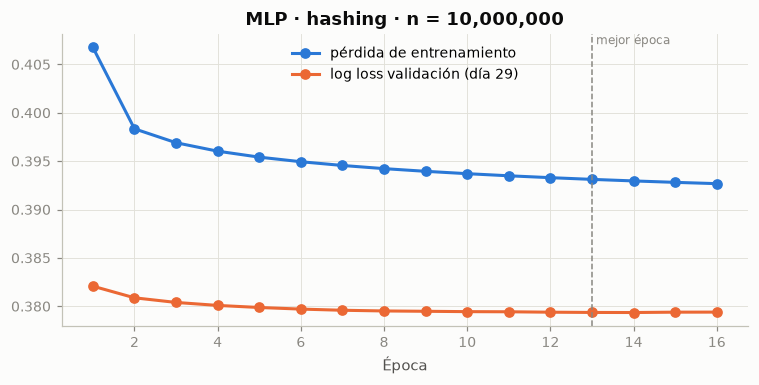

In [7]:
# curva de entrenamiento del MLP (época a época) en la corrida más grande con hashing
h = runs[(runs.model == "mlp") & (runs.encoding == "hash") & runs["history"].notna()].sort_values("n").iloc[-1]
hist = pd.DataFrame(h["history"])
fig, ax = plt.subplots(figsize=(7, 3.6))
ax.plot(hist["epoch"], hist["train_loss"], marker="o", color=SERIES[0], label="pérdida de entrenamiento")
ax.plot(hist["epoch"], hist["val_log_loss"], marker="o", color=SERIES[1], label="log loss validación (día 29)")
ax.axvline(h["best_epoch"], color=MUTED, linestyle="--", linewidth=1)
ax.text(h["best_epoch"], ax.get_ylim()[1], " mejor época", color=MUTED, va="top", fontsize=8)
ax.set_xlabel("Época"); ax.set_title(f"MLP · hashing · n = {int(h['n']):,}"); ax.legend()
savefig(fig, FIG, "04_mlp_epocas")

## 4.4 Ablaciones (n = `ablation_size`, varias semillas)

In [8]:
NA = cfg["ablation_size"]
seeds_abl = cfg.seeds[: cfg["ablation_seeds"]]
done_abl = done_keys(ABL)
tr = data.read_sample(cfg, "train", NA); ytr = tr["click"].to_numpy()
feat = CTRFeaturizer(cfg.high_card, cfg.low_card, cfg["rare_min_count"]).fit(tr)
c_tr, c_va, c_te = feat.encode(tr), feat.encode(va), feat.encode(te)

def abl(factor, nivel, model, enc, dim, params, s, cw=None, f=feat, ctr=c_tr, cva=c_va, cte=c_te):
    key = run_key(factor=factor, nivel=nivel, model=model, seed=s)
    if key in done_abl:
        return
    Xtr = f.transform_codes(ctr, enc, dim, y=ytr, fit=True)
    rec, _, _ = run_sk_model(model, Xtr, ytr, f.transform_codes(cva, enc, dim), yva,
                             f.transform_codes(cte, enc, dim), yte, s, params, cw,
                             cfg["max_epochs"], cfg["patience"])
    rec.update({"key": key, "factor": factor, "nivel": str(nivel), "encoding": enc, "n": NA,
                "dim_entrada": Xtr.shape[1]})
    append_jsonl(ABL, rec)

for s in seeds_abl:
    for dim in cfg["hash_dims"]:                                   # dimensión del hashing
        abl("dimension_hashing", f"2^{int(np.log2(dim))}", "mlp", "hash", dim, PARAMS, s)
    for hl in cfg["mlp_search_space"]["hidden_layer_sizes"]:       # profundidad / ancho
        abl("arquitectura", hl, "mlp", "hash", DIM, dict(PARAMS, hidden_layer_sizes=hl), s)
    for m in ["mlp", "sgd", "hgb"]:                                 # ponderación de clases
        enc = "hash" if m != "hgb" else "freq"
        for cw in [None, "balanced"]:
            abl("ponderacion_clases", f"{m}:{cw or 'ninguna'}", m, enc, DIM, PARAMS, s, cw)
    abl("parada_temprana", "temporal (día 29)", "mlp", "hash", DIM, PARAMS, s)
    abl("parada_temprana", "interna aleatoria (enunciado)", "mlp_es_interna", "hash", DIM, PARAMS, s)

feat_x = CTRFeaturizer(cfg.high_card, cfg.low_card, cfg["rare_min_count"], crosses=cfg["features"]["crosses"]).fit(tr)
cx_tr, cx_va, cx_te = feat_x.encode(tr), feat_x.encode(va), feat_x.encode(te)
for s in seeds_abl:                                                # cruces de variables
    abl("cruces", "sin cruces", "mlp", "hash", DIM, PARAMS, s)
    abl("cruces", "con cruces", "mlp", "hash", DIM, PARAMS, s, None, feat_x, cx_tr, cx_va, cx_te)

ab = read_jsonl(ABL)
tab_abl = summarize_runs(ab, ["factor", "nivel"], ["roc_auc", "pr_auc", "log_loss", "ece", "f1", "recall", "train_s"])
tab_abl.to_csv(RES / "tabla_ablaciones_sklearn.csv", index=False)
show(tab_abl[["factor", "nivel", "n_semillas", "roc_auc_media", "roc_auc_sd", "pr_auc_media", "log_loss_media",
              "ece_media", "f1_media", "recall_media", "train_s_media"]], 40)

,factor,nivel,n_semillas,roc_auc_media,roc_auc_sd,pr_auc_media,log_loss_media,ece_media,f1_media,recall_media,train_s_media
0,arquitectura,100,3,0.7295,0.0002,0.3562,0.4064,0.0084,0.4093,0.6386,63.2296
1,arquitectura,100-50,3,0.7292,0.0012,0.3561,0.4067,0.0093,0.4089,0.6458,49.9558
2,arquitectura,256-128,3,0.7287,0.0012,0.3556,0.4068,0.0091,0.4076,0.6314,99.9794
3,arquitectura,50,3,0.7284,0.0002,0.3548,0.4068,0.0080,0.4077,0.6446,38.1482
4,cruces,con cruces,3,0.7312,0.0001,0.3581,0.4056,0.0075,0.4112,0.6517,57.9800
5,cruces,sin cruces,3,0.7295,0.0002,0.3562,0.4064,0.0084,0.4093,0.6386,64.7425
6,dimension_hashing,2^12,3,0.7269,0.0012,0.3540,0.4077,0.0092,0.4071,0.6349,33.6252
7,dimension_hashing,2^14,3,0.7295,0.0002,0.3562,0.4064,0.0084,0.4093,0.6386,63.1724
8,dimension_hashing,2^16,3,0.7276,0.0010,0.3538,0.4069,0.0072,0.4070,0.6602,156.3960
9,parada_temprana,interna aleatoria (enunciado),3,0.7280,0.0012,0.3546,0.4068,0.0081,0.4078,0.6367,44.2227


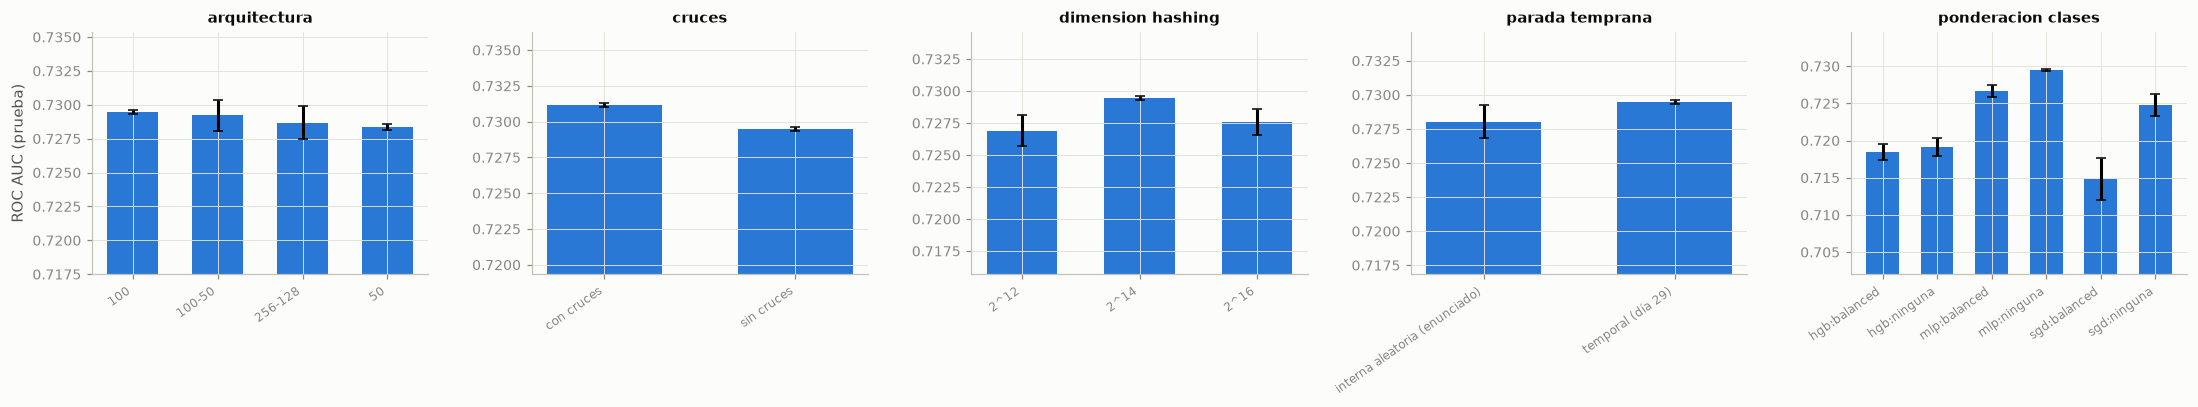

In [9]:
facs = list(tab_abl["factor"].unique())
fig, axs = plt.subplots(1, len(facs), figsize=(4 * len(facs), 3.8), squeeze=False)
for ax, fac in zip(axs[0], facs):
    t = tab_abl[tab_abl.factor == fac]
    ax.bar(range(len(t)), t["roc_auc_media"], yerr=t["roc_auc_sd"].fillna(0), color=SERIES[0], width=0.6, capsize=3)
    ax.set_xticks(range(len(t)), t["nivel"], rotation=35, ha="right", fontsize=8)
    lo = (t["roc_auc_media"] - t["roc_auc_sd"].fillna(0)).min()
    ax.set_ylim(lo - 0.01, (t["roc_auc_media"] + t["roc_auc_sd"].fillna(0)).max() + 0.005)
    ax.set_title(fac.replace("_", " "), fontsize=10)
axs[0][0].set_ylabel("ROC AUC (prueba)")
savefig(fig, FIG, "04_ablaciones")